# Model 1: regresja — `streams`

## 1. Przygotowanie

### Importy

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm

from sklearn import model_selection, linear_model, metrics, ensemble, dummy
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

### Wczytanie danych i wybór zmiennych

In [4]:
df = pd.read_csv('/Users/majazontek/Desktop/UCZELNIA/3 rok/SEMINARIUM LICENCJACKIE/MACHINE LEARNING/dane/viral_songs.csv')  # podmień ścieżkę

NUM_FEATURES = [
    "release_year", "duration_sec", "danceability", "energy", "valence", "tempo_bpm",
    "acousticness", "instrumentalness", "speechiness", "liveness", "loudness_db",
]
CAT_FEATURES = ["genre"]
TARGET = "streams" #zmienna ktora bedziemy modelowac (objasniana)

X = df[NUM_FEATURES + CAT_FEATURES]
y = df[TARGET]
print(X.shape, y.shape)

(10000, 12) (10000,)


### Podział na zbiór treningowy i testowy

In [5]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(
    X, y, train_size=0.7, random_state=42
)
print("train:", X_train.shape, "test:", X_test.shape)

train: (7000, 12) test: (3000, 12)


### Przygotowanie cech i szablon modelu

- `StandardScaler`: średnia = 0, odchylenie standardowe = 1
- one-hot encoding: zamiana zmiennej `genre` na 9 zmiennych 0/1, bo model nie czyta słów
- `make_model`: model uczony na `log10(streams)`, predykcje w oryginalnej skali `streams`

In [6]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUM_FEATURES),
    ("cat", OneHotEncoder(drop="first"), CAT_FEATURES),
])

def make_model(regressor):
    pipe = Pipeline([("prep", preprocess), ("reg", regressor)])
    return TransformedTargetRegressor(
        regressor=pipe, func=np.log10, inverse_func=lambda z: 10 ** z
    )

### Funkcje pomocnicze (z podręcznika)

In [7]:
def sse(resid):
    return np.sum(resid ** 2)

def r2_log(y_true, y_pred):
    return metrics.r2_score(np.log10(y_true), np.log10(y_pred))

def evaluate(model, X_tr, y_tr, X_te, y_te):
    pred_tr, pred_te = model.predict(X_tr), model.predict(X_te)
    return {
        "R2_log_train": r2_log(y_tr, pred_tr),
        "R2_log_test": r2_log(y_te, pred_te),
        "R2_test": metrics.r2_score(y_te, pred_te),
        "MAE_test": metrics.mean_absolute_error(y_te, pred_te),
        "MedAE_test": metrics.median_absolute_error(y_te, pred_te),
    }

def feature_names(model):
    return model.regressor_.named_steps["prep"].get_feature_names_out()

def plot_residuals_and_coeff(resid_train, resid_test, coeff, names, title):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].bar(np.arange(len(resid_train)), resid_train)
    axes[0].set_xlabel("numer próbki")
    axes[0].set_ylabel("reszta")
    axes[0].set_title("zbiór treningowy")
    axes[1].bar(np.arange(len(resid_test)), resid_test)
    axes[1].set_xlabel("numer próbki")
    axes[1].set_ylabel("reszta")
    axes[1].set_title("zbiór testowy")
    axes[2].bar(np.arange(len(coeff)), coeff)
    axes[2].set_xticks(np.arange(len(coeff)), names, rotation=90)
    axes[2].set_ylabel("współczynnik")
    axes[2].set_title("współczynniki")
    fig.suptitle(title)
    fig.tight_layout()
    return fig, axes

### Funkcja pomocnicza: ważność cech jak `varImp` w R

In [8]:
def var_imp(values, title, signed=None):
    values = pd.Series(values)
    rng = values.max() - values.min()
    overall = 100 * (values - values.min()) / rng if rng > 0 else values * 0
    table = pd.DataFrame({"Overall": overall})
    if signed is not None:
        table.insert(0, "współczynnik", signed)
    table = table.sort_values("Overall", ascending=False)
    display(table.round(4))

    colors = "grey"
    if signed is not None:
        colors = np.where(table["współczynnik"] >= 0, "tab:blue", "tab:red")[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(table) + 1))
    ax.barh(table.index[::-1], table["Overall"][::-1], color=colors)
    ax.set_xlabel("ważność (0–100)")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

## 2. Model bazowy

`DummyRegressor` ignoruje cechy i dla każdego utworu przewiduje tę samą wartość: średnią z `log10(streams)` w zbiorze treningowym. Jest punktem odniesienia, bo każdy model powinien być od niego lepszy.

In [9]:
baseline = make_model(dummy.DummyRegressor(strategy="mean"))
baseline.fit(X_train, y_train)
results = {"Dummy (średnia)": evaluate(baseline, X_train, y_train, X_test, y_test)}
pd.DataFrame(results).T

,R2_log_train,R2_log_test,R2_test,MAE_test,MedAE_test
Dummy (średnia),0.0,-0.000008,-0.042517,2.344576e+06,307895.332646


## 3. Regresja liniowa

In [10]:
lin = make_model(linear_model.LinearRegression())
lin.fit(X_train, y_train)
results["LinearRegression"] = evaluate(lin, X_train, y_train, X_test, y_test)
pd.DataFrame(results).T

,R2_log_train,R2_log_test,R2_test,MAE_test,MedAE_test
Dummy (średnia),0.000000,-0.000008,-0.042517,2.344576e+06,307895.332646
LinearRegression,0.100256,0.078901,-0.034186,2.315372e+06,337733.384032


### Reszty i współczynniki

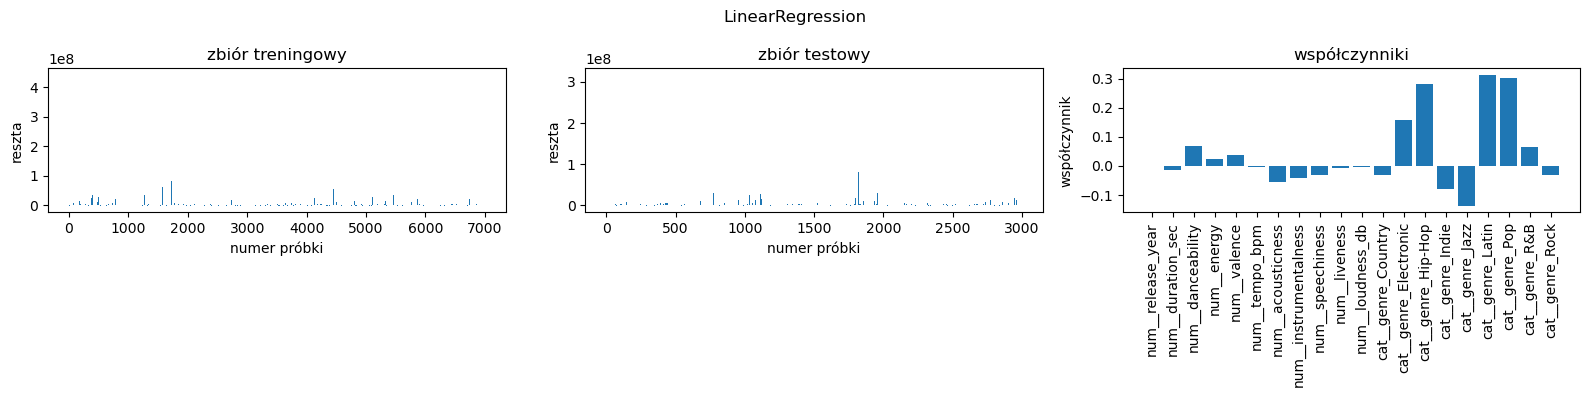

In [11]:
coef = lin.regressor_.named_steps["reg"].coef_
resid_train = y_train - lin.predict(X_train)
resid_test = y_test - lin.predict(X_test)
fig, ax = plot_residuals_and_coeff(resid_train, resid_test, coef, feature_names(lin), "LinearRegression")
plt.show()

### Summary i ważność cech

                            OLS Regression Results                            
Dep. Variable:                streams   R-squared:                       0.100
Model:                            OLS   Adj. R-squared:                  0.098
Method:                 Least Squares   F-statistic:                     38.88
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          1.78e-143
Time:                        21:13:10   Log-Likelihood:                -8626.4
No. Observations:                7000   AIC:                         1.729e+04
Df Residuals:                    6979   BIC:                         1.744e+04
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     5.45

,współczynnik,Overall
num__danceability,0.0701,100.0000
num__instrumentalness,-0.0412,94.0342
cat__genre_Pop,0.3018,79.8737
cat__genre_Latin,0.3132,78.9089
num__valence,0.0394,74.5602
cat__genre_Hip-Hop,0.2823,73.9917
num__speechiness,-0.0321,73.2652
num__acousticness,-0.0537,60.5315
cat__genre_Jazz,-0.1366,55.5927
cat__genre_Electronic,0.1582,37.9040


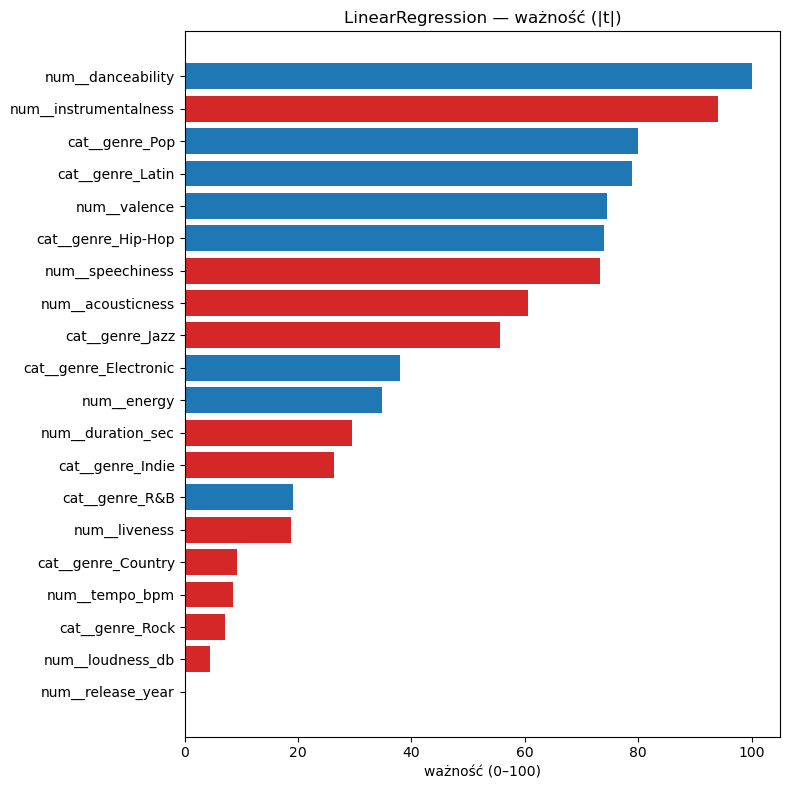

In [12]:
prep = lin.regressor_.named_steps["prep"]
X_train_prep = pd.DataFrame(prep.transform(X_train), columns=feature_names(lin), index=X_train.index)

ols = sm.OLS(np.log10(y_train), sm.add_constant(X_train_prep)).fit()
print(ols.summary())

var_imp(ols.tvalues.drop("const").abs(), "LinearRegression — ważność (|t|)",
        signed=ols.params.drop("const"))

## 4. Regresja Ridge

In [13]:
ridge = make_model(linear_model.Ridge(alpha=2.5))
ridge.fit(X_train, y_train)
results["Ridge (α = 2.5)"] = evaluate(ridge, X_train, y_train, X_test, y_test)
pd.DataFrame(results).T

,R2_log_train,R2_log_test,R2_test,MAE_test,MedAE_test
Dummy (średnia),0.000000,-0.000008,-0.042517,2.344576e+06,307895.332646
LinearRegression,0.100256,0.078901,-0.034186,2.315372e+06,337733.384032
Ridge (α = 2.5),0.100248,0.078991,-0.034202,2.315314e+06,335726.742846


### Reszty i współczynniki

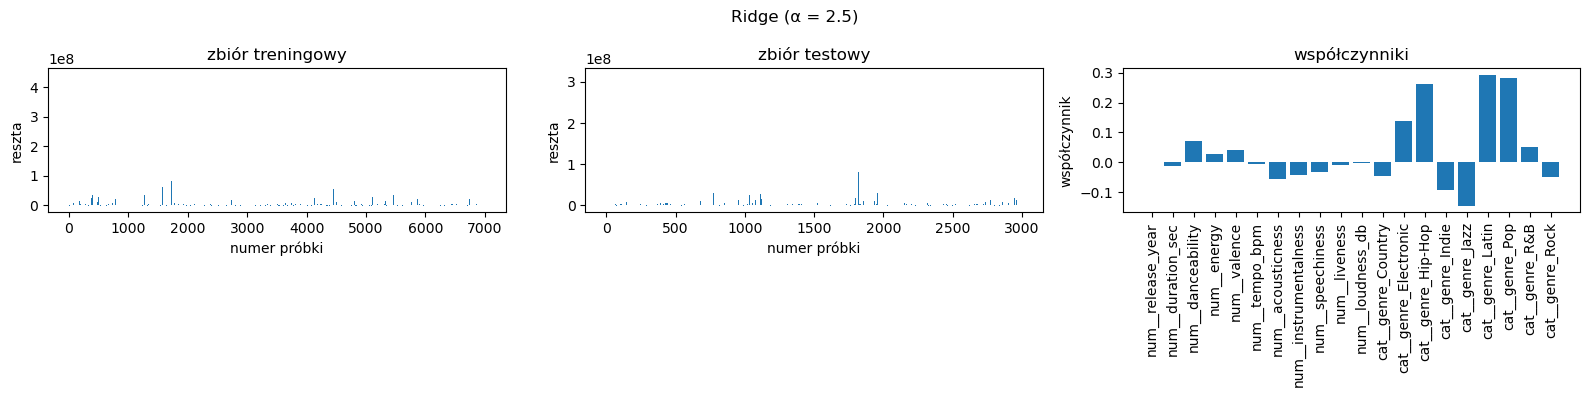

In [14]:
coef = ridge.regressor_.named_steps["reg"].coef_
resid_train = y_train - ridge.predict(X_train)
resid_test = y_test - ridge.predict(X_test)
fig, ax = plot_residuals_and_coeff(resid_train, resid_test, coef, feature_names(ridge), "Ridge (α = 2.5)")
plt.show()

### Ważność cech

,współczynnik,Overall
cat__genre_Latin,0.2926,100.0000
cat__genre_Pop,0.2824,96.5090
cat__genre_Hip-Hop,0.2627,89.7800
cat__genre_Jazz,-0.1453,49.6010
cat__genre_Electronic,0.1376,46.9830
cat__genre_Indie,-0.0923,31.4722
num__danceability,0.0720,24.5229
num__acousticness,-0.0568,19.3400
cat__genre_R&B,0.0501,17.0512
cat__genre_Rock,-0.0475,16.1497


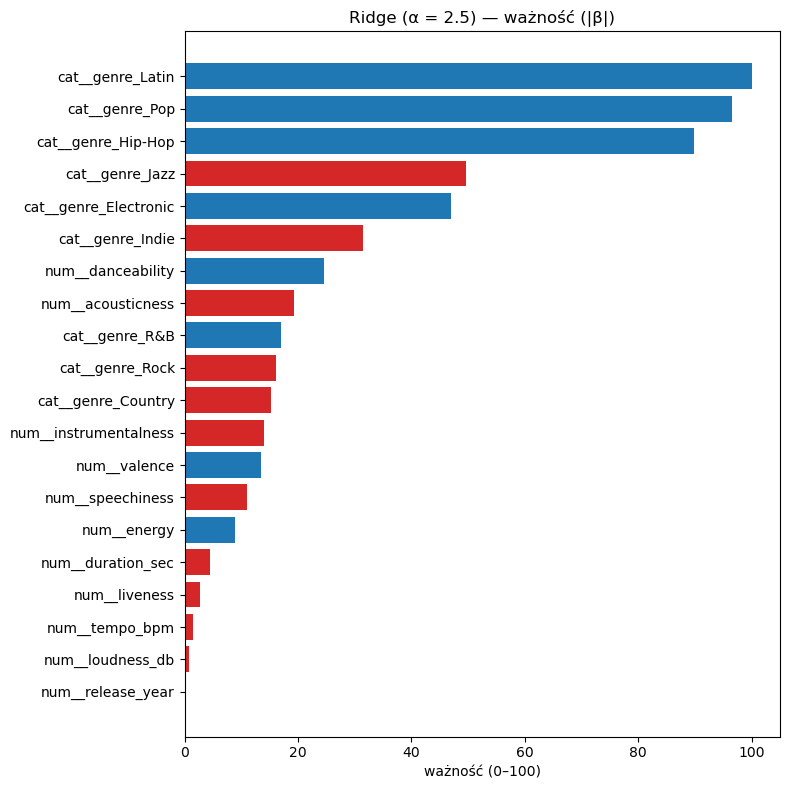

In [15]:
var_imp(np.abs(pd.Series(ridge.regressor_.named_steps["reg"].coef_, index=feature_names(ridge))),
        "Ridge (α = 2.5) — ważność (|β|)",
        signed=ridge.regressor_.named_steps["reg"].coef_)

## 5. Regresja LASSO

In [16]:
lasso = make_model(linear_model.Lasso(alpha=0.01))
lasso.fit(X_train, y_train)
results["Lasso (α = 0.01)"] = evaluate(lasso, X_train, y_train, X_test, y_test)
pd.DataFrame(results).T

,R2_log_train,R2_log_test,R2_test,MAE_test,MedAE_test
Dummy (średnia),0.000000,-0.000008,-0.042517,2.344576e+06,307895.332646
LinearRegression,0.100256,0.078901,-0.034186,2.315372e+06,337733.384032
Ridge (α = 2.5),0.100248,0.078991,-0.034202,2.315314e+06,335726.742846
Lasso (α = 0.01),0.088868,0.070662,-0.036386,2.319272e+06,331301.326123


### Reszty i współczynniki

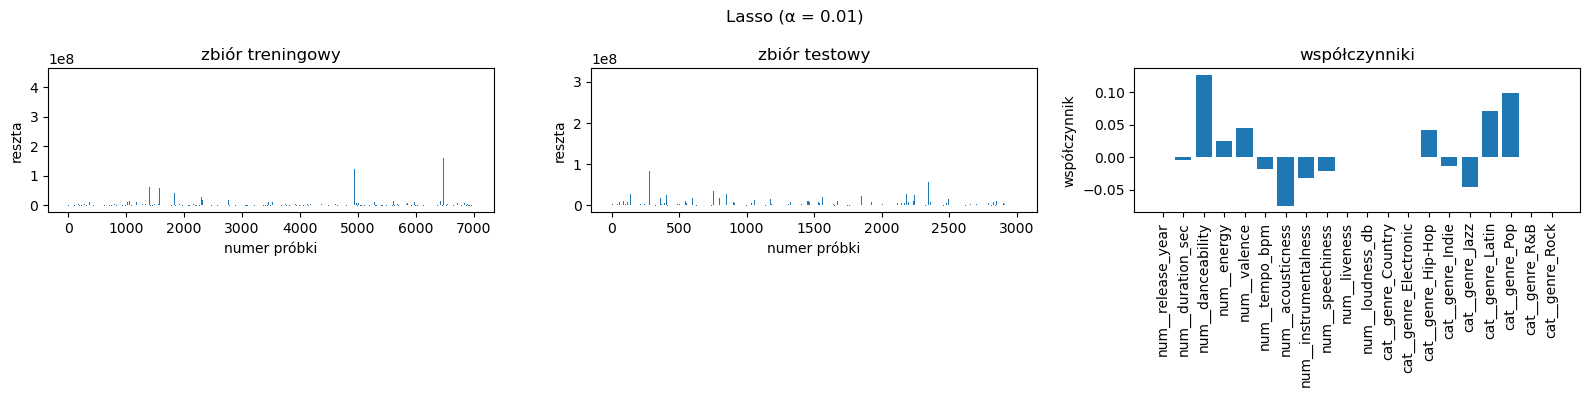

In [17]:
coef = lasso.regressor_.named_steps["reg"].coef_
resid_train = y_train - lasso.predict(X_train)
resid_test = y_test - lasso.predict(X_test)
fig, ax = plot_residuals_and_coeff(resid_train, resid_test, coef, feature_names(lasso), "Lasso (α = 0.01)")
plt.show()

### Ważność cech

,współczynnik,Overall
num__danceability,0.1269,100.0000
cat__genre_Pop,0.0993,78.2948
num__acousticness,-0.0748,58.9968
cat__genre_Latin,0.0706,55.6513
cat__genre_Jazz,-0.0462,36.4023
num__valence,0.0449,35.3540
cat__genre_Hip-Hop,0.0423,33.3762
num__instrumentalness,-0.0319,25.1801
num__energy,0.0253,19.9346
num__speechiness,-0.0214,16.8706


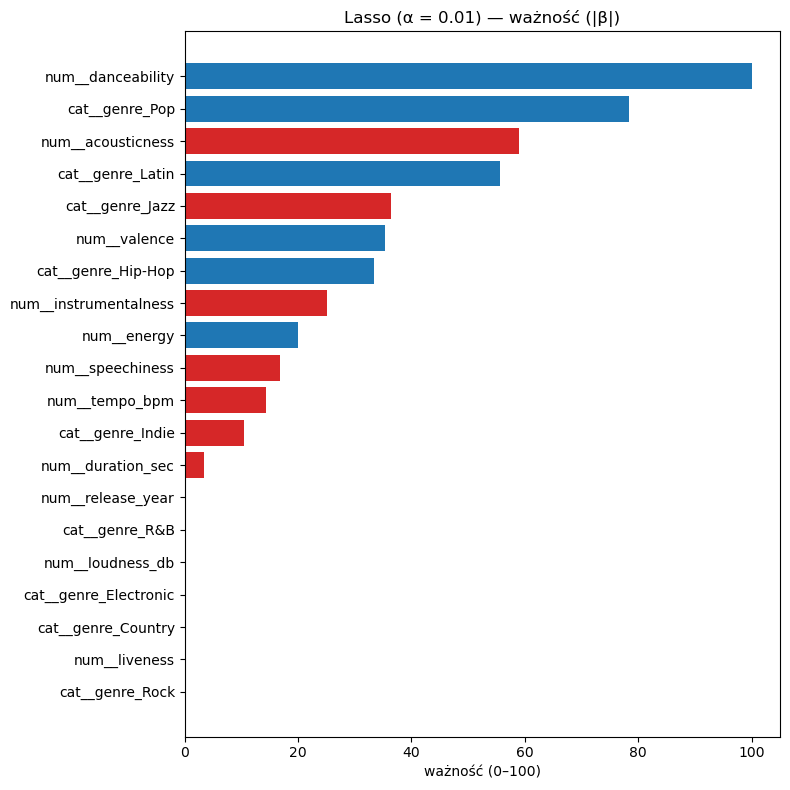

In [18]:
var_imp(np.abs(pd.Series(lasso.regressor_.named_steps["reg"].coef_, index=feature_names(lasso))),
        "Lasso (α = 0.01) — ważność (|β|)",
        signed=lasso.regressor_.named_steps["reg"].coef_)

## 6. Wpływ α na model: ścieżka LASSO

### Pętla po α

In [19]:
alphas = np.logspace(-4, 0, 50)
names = feature_names(lasso)
coeffs = np.zeros((len(alphas), len(names)))
sse_train = np.zeros_like(alphas)
sse_test = np.zeros_like(alphas)

for n, alpha in enumerate(alphas):
    model = make_model(linear_model.Lasso(alpha=alpha))
    model.fit(X_train, y_train)
    coeffs[n, :] = model.regressor_.named_steps["reg"].coef_
    sse_train[n] = sse(np.log10(y_train) - np.log10(model.predict(X_train)))
    sse_test[n] = sse(np.log10(y_test) - np.log10(model.predict(X_test)))

### Wykres ścieżki LASSO

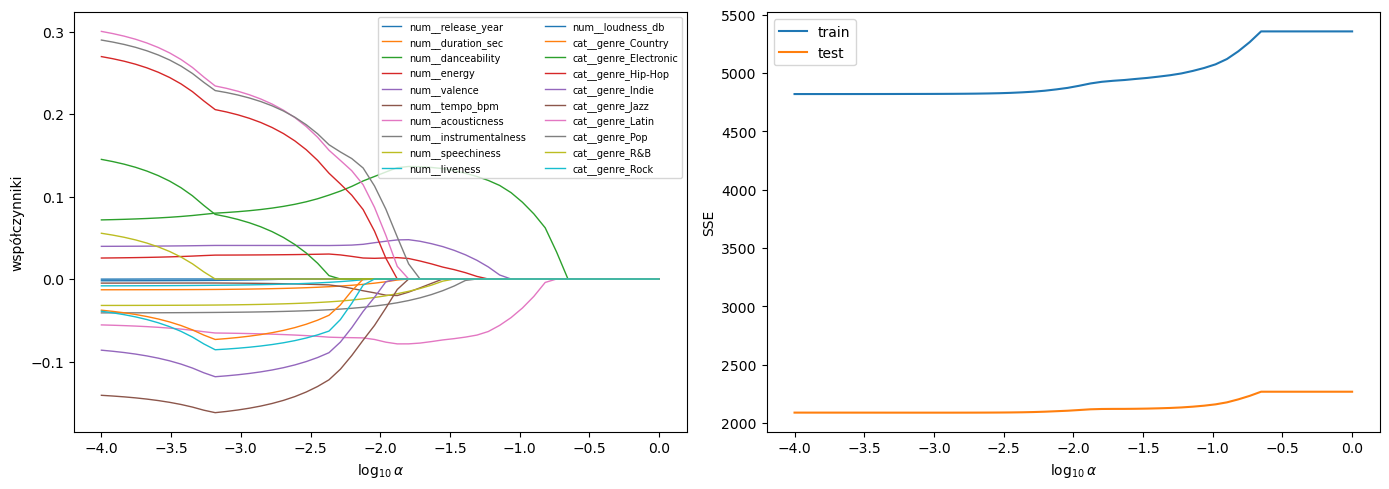

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for i, name in enumerate(names):
    axes[0].plot(np.log10(alphas), coeffs[:, i], lw=1, label=name)
axes[0].set_xlabel(r"$\log_{10}\alpha$")
axes[0].set_ylabel("współczynniki")
axes[0].legend(fontsize=7, ncol=2)

axes[1].plot(np.log10(alphas), sse_train, label="train")
axes[1].plot(np.log10(alphas), sse_test, label="test")
axes[1].set_xlabel(r"$\log_{10}\alpha$")
axes[1].set_ylabel("SSE")
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Dobór α przez walidację krzyżową

### RidgeCV

In [21]:
ridge_cv = make_model(linear_model.RidgeCV(alphas=np.logspace(-4, 4, 100), cv=5))
ridge_cv.fit(X_train, y_train)
print("RidgeCV α =", ridge_cv.regressor_.named_steps["reg"].alpha_)
results["RidgeCV"] = evaluate(ridge_cv, X_train, y_train, X_test, y_test)
display(pd.DataFrame(results).T)

RidgeCV α = 45.34878508128591


,R2_log_train,R2_log_test,R2_test,MAE_test,MedAE_test
Dummy (średnia),0.000000,-0.000008,-0.042517,2.344576e+06,307895.332646
LinearRegression,0.100256,0.078901,-0.034186,2.315372e+06,337733.384032
Ridge (α = 2.5),0.100248,0.078991,-0.034202,2.315314e+06,335726.742846
Lasso (α = 0.01),0.088868,0.070662,-0.036386,2.319272e+06,331301.326123
RidgeCV,0.099942,0.079044,-0.034427,2.315230e+06,334013.290166


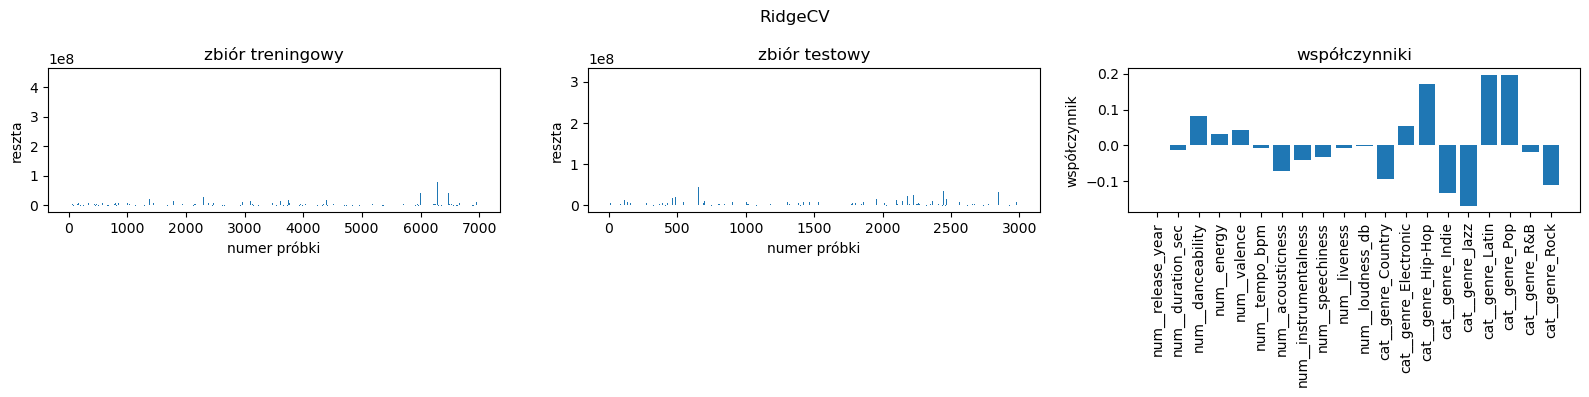

In [22]:
coef = ridge_cv.regressor_.named_steps["reg"].coef_
resid_train = y_train - ridge_cv.predict(X_train)
resid_test = y_test - ridge_cv.predict(X_test)
fig, ax = plot_residuals_and_coeff(resid_train, resid_test, coef, feature_names(ridge_cv), "RidgeCV")
plt.show()

,współczynnik,Overall
cat__genre_Latin,0.1965,100.0000
cat__genre_Pop,0.1955,99.5004
cat__genre_Hip-Hop,0.1720,87.5461
cat__genre_Jazz,-0.1679,85.4616
cat__genre_Indie,-0.1323,67.3188
cat__genre_Rock,-0.1103,56.0956
cat__genre_Country,-0.0945,48.0489
num__danceability,0.0831,42.2795
num__acousticness,-0.0702,35.6647
cat__genre_Electronic,0.0529,26.8749


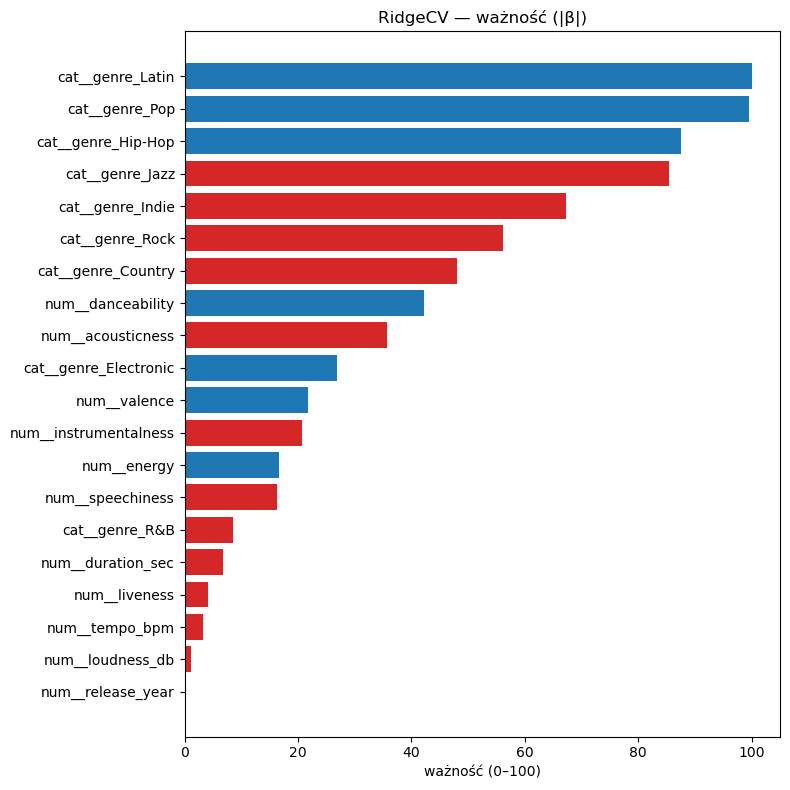

In [23]:
var_imp(np.abs(pd.Series(ridge_cv.regressor_.named_steps["reg"].coef_, index=feature_names(ridge_cv))),
        "RidgeCV — ważność (|β|)",
        signed=ridge_cv.regressor_.named_steps["reg"].coef_)

### LassoCV

In [24]:
lasso_cv = make_model(linear_model.LassoCV(cv=5, random_state=42))
lasso_cv.fit(X_train, y_train)
print("LassoCV α =", lasso_cv.regressor_.named_steps["reg"].alpha_)
results["LassoCV"] = evaluate(lasso_cv, X_train, y_train, X_test, y_test)
display(pd.DataFrame(results).T)

LassoCV α = 0.0009390712606802701


,R2_log_train,R2_log_test,R2_test,MAE_test,MedAE_test
Dummy (średnia),0.000000,-0.000008,-0.042517,2.344576e+06,307895.332646
LinearRegression,0.100256,0.078901,-0.034186,2.315372e+06,337733.384032
Ridge (α = 2.5),0.100248,0.078991,-0.034202,2.315314e+06,335726.742846
Lasso (α = 0.01),0.088868,0.070662,-0.036386,2.319272e+06,331301.326123
RidgeCV,0.099942,0.079044,-0.034427,2.315230e+06,334013.290166
LassoCV,0.100032,0.079135,-0.034424,2.315254e+06,333744.042187


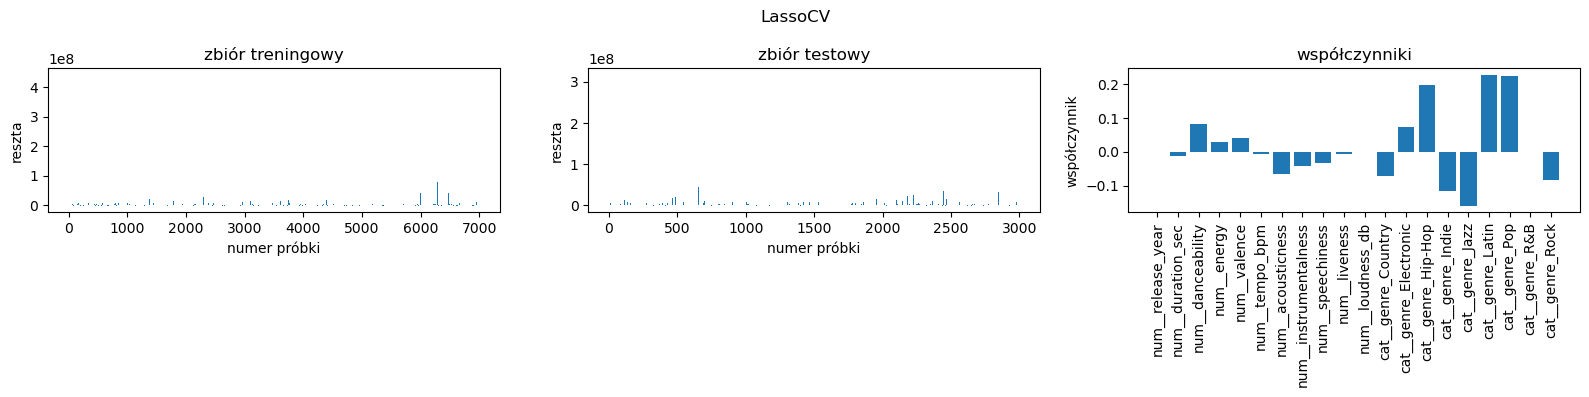

In [25]:
coef = lasso_cv.regressor_.named_steps["reg"].coef_
resid_train = y_train - lasso_cv.predict(X_train)
resid_test = y_test - lasso_cv.predict(X_test)
fig, ax = plot_residuals_and_coeff(resid_train, resid_test, coef, feature_names(lasso_cv), "LassoCV")
plt.show()

,współczynnik,Overall
cat__genre_Latin,0.2279,100.0000
cat__genre_Pop,0.2233,97.9708
cat__genre_Hip-Hop,0.1993,87.4512
cat__genre_Jazz,-0.1589,69.7279
cat__genre_Indie,-0.1162,50.9756
cat__genre_Rock,-0.0840,36.8561
num__danceability,0.0815,35.7676
cat__genre_Electronic,0.0725,31.8161
cat__genre_Country,-0.0710,31.1548
num__acousticness,-0.0658,28.8886


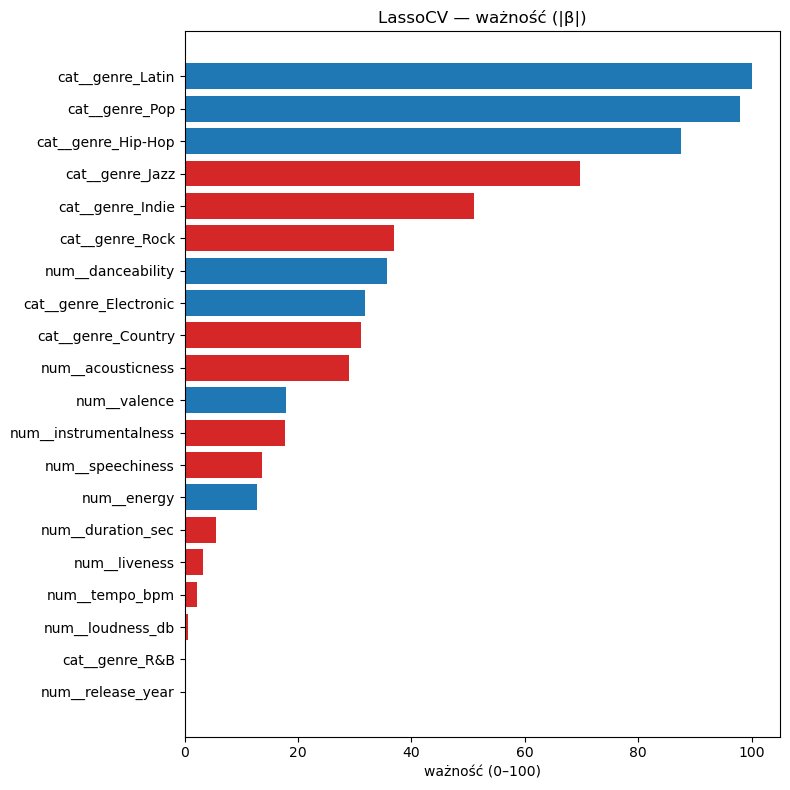

In [26]:
var_imp(np.abs(pd.Series(lasso_cv.regressor_.named_steps["reg"].coef_, index=feature_names(lasso_cv))),
        "LassoCV — ważność (|β|)",
        signed=lasso_cv.regressor_.named_steps["reg"].coef_)

### ElasticNetCV

In [27]:
enet_cv = make_model(linear_model.ElasticNetCV(l1_ratio=[0.1, 0.5, 0.7, 0.9, 0.95, 1], cv=5, random_state=42))
enet_cv.fit(X_train, y_train)
print("ElasticNetCV α =", enet_cv.regressor_.named_steps["reg"].alpha_,
      " l1_ratio =", enet_cv.regressor_.named_steps["reg"].l1_ratio_)
results["ElasticNetCV"] = evaluate(enet_cv, X_train, y_train, X_test, y_test)
display(pd.DataFrame(results).T)

ElasticNetCV α = 0.0035355430144648923  l1_ratio = 0.1


,R2_log_train,R2_log_test,R2_test,MAE_test,MedAE_test
Dummy (średnia),0.000000,-0.000008,-0.042517,2.344576e+06,307895.332646
LinearRegression,0.100256,0.078901,-0.034186,2.315372e+06,337733.384032
Ridge (α = 2.5),0.100248,0.078991,-0.034202,2.315314e+06,335726.742846
Lasso (α = 0.01),0.088868,0.070662,-0.036386,2.319272e+06,331301.326123
RidgeCV,0.099942,0.079044,-0.034427,2.315230e+06,334013.290166
LassoCV,0.100032,0.079135,-0.034424,2.315254e+06,333744.042187
ElasticNetCV,0.100039,0.079151,-0.034405,2.315226e+06,334357.487425


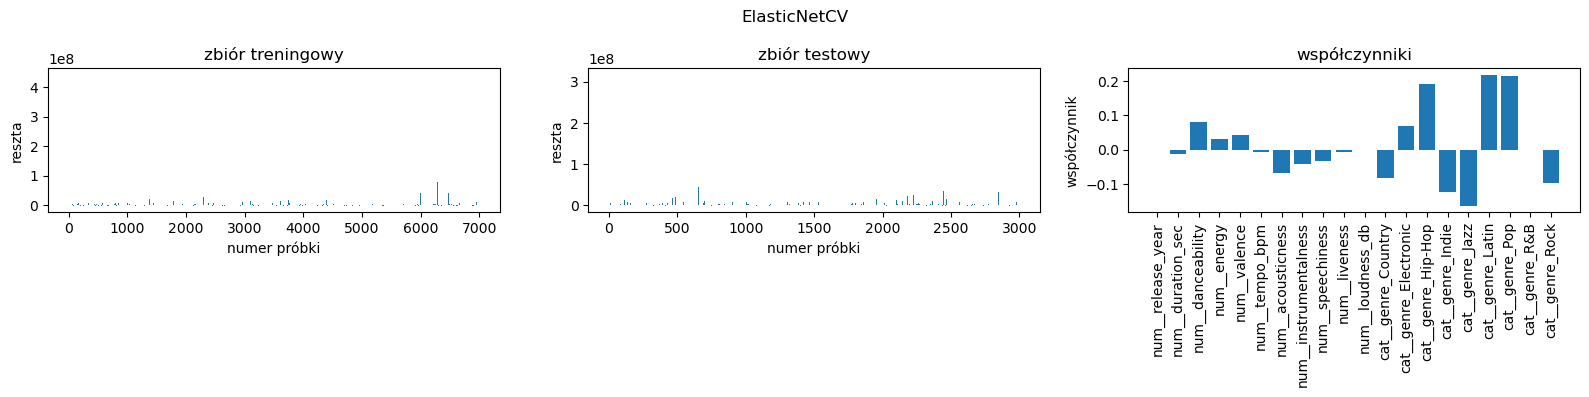

In [28]:
coef = enet_cv.regressor_.named_steps["reg"].coef_
resid_train = y_train - enet_cv.predict(X_train)
resid_test = y_test - enet_cv.predict(X_test)
fig, ax = plot_residuals_and_coeff(resid_train, resid_test, coef, feature_names(enet_cv), "ElasticNetCV")
plt.show()

,współczynnik,Overall
cat__genre_Latin,0.2181,100.0000
cat__genre_Pop,0.2144,98.3083
cat__genre_Hip-Hop,0.1919,87.9852
cat__genre_Jazz,-0.1629,74.6942
cat__genre_Indie,-0.1233,56.5268
cat__genre_Rock,-0.0955,43.8073
cat__genre_Country,-0.0816,37.3917
num__danceability,0.0811,37.1710
cat__genre_Electronic,0.0680,31.1650
num__acousticness,-0.0670,30.7207


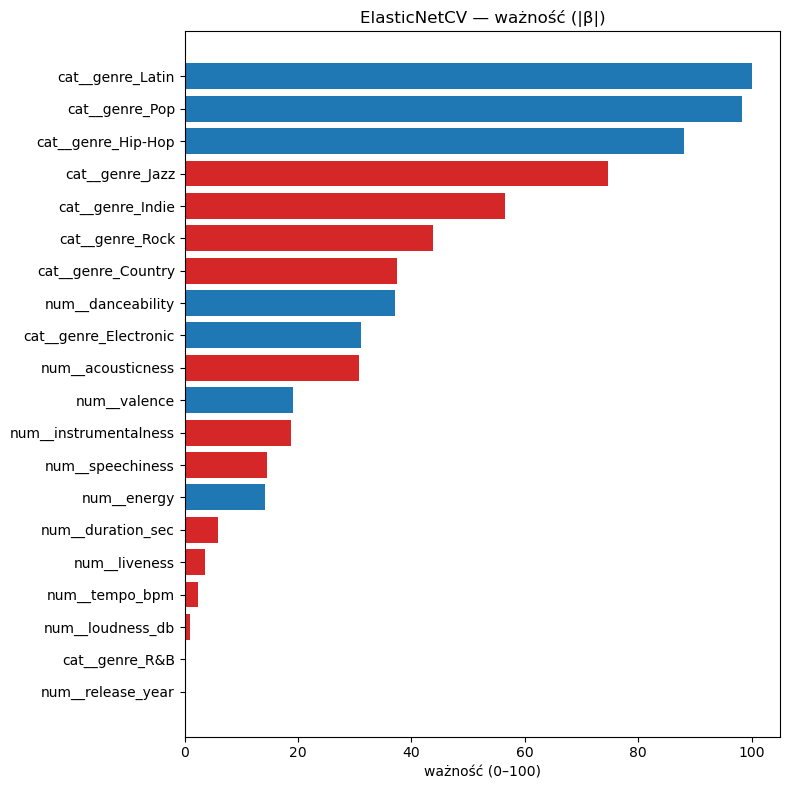

In [29]:
var_imp(np.abs(pd.Series(enet_cv.regressor_.named_steps["reg"].coef_, index=feature_names(enet_cv))),
        "ElasticNetCV — ważność (|β|)",
        signed=enet_cv.regressor_.named_steps["reg"].coef_)

## 8. Random Forest

Model nieliniowy: średnia predykcji wielu drzew decyzyjnych uczonych na losowych podpróbach danych i cech. Może wychwycić interakcje i nieliniowości, których modele liniowe nie widzą.

Parametry:
- `n_estimators=300`: liczba drzew
- `min_samples_leaf=5`: minimalna liczba obserwacji w liściu

In [30]:
rf = make_model(ensemble.RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42))
rf.fit(X_train, y_train)
results["RandomForest"] = evaluate(rf, X_train, y_train, X_test, y_test)
pd.DataFrame(results).T

,R2_log_train,R2_log_test,R2_test,MAE_test,MedAE_test
Dummy (średnia),0.000000,-0.000008,-0.042517,2.344576e+06,307895.332646
LinearRegression,0.100256,0.078901,-0.034186,2.315372e+06,337733.384032
Ridge (α = 2.5),0.100248,0.078991,-0.034202,2.315314e+06,335726.742846
Lasso (α = 0.01),0.088868,0.070662,-0.036386,2.319272e+06,331301.326123
RidgeCV,0.099942,0.079044,-0.034427,2.315230e+06,334013.290166
LassoCV,0.100032,0.079135,-0.034424,2.315254e+06,333744.042187
ElasticNetCV,0.100039,0.079151,-0.034405,2.315226e+06,334357.487425
RandomForest,0.636586,0.065929,-0.033780,2.320195e+06,357477.978370


### Ważność cech

Permutation importance: spadek R² na zbiorze testowym po wymieszaniu wartości danej cechy.

Wymieszanie: kolumnę jednej cechy w zbiorze testowym losowo przestawiamy między wierszami. Wszystkie inne kolumny i zmienna celu zostają na swoich miejscach.

,Overall
num__danceability,100.0000
num__acousticness,65.9550
num__valence,56.4039
num__tempo_bpm,51.4229
num__energy,50.9584
num__loudness_db,50.8168
num__liveness,50.7747
num__duration_sec,50.1573
num__speechiness,45.7066
num__instrumentalness,44.3205


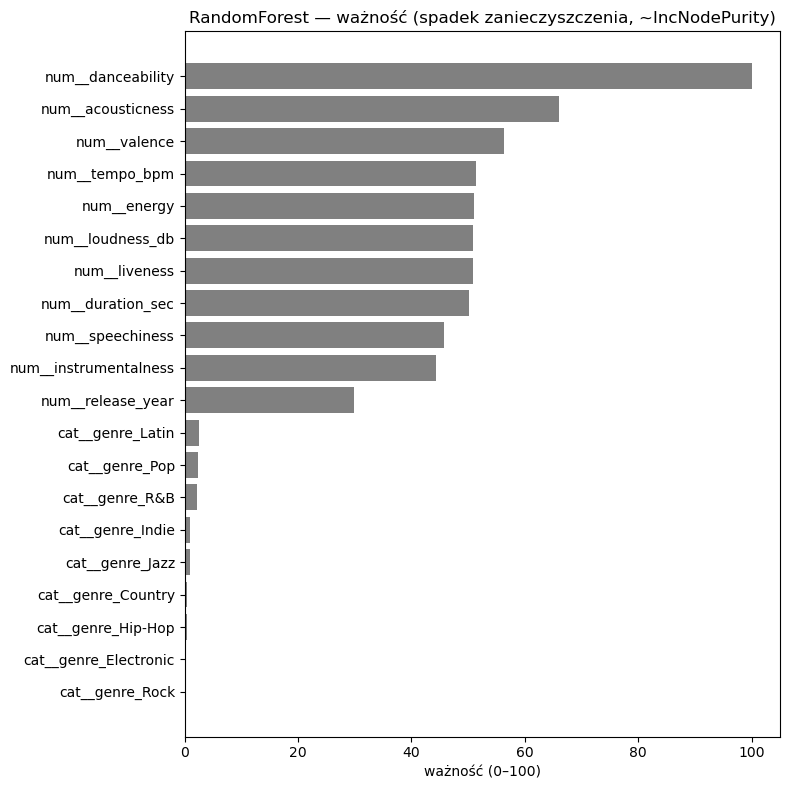

,Overall
danceability,100.0000
acousticness,64.1501
genre,19.9690
valence,13.1349
duration_sec,7.8239
instrumentalness,7.3127
energy,7.0151
loudness_db,4.6593
speechiness,1.7301
liveness,0.9878


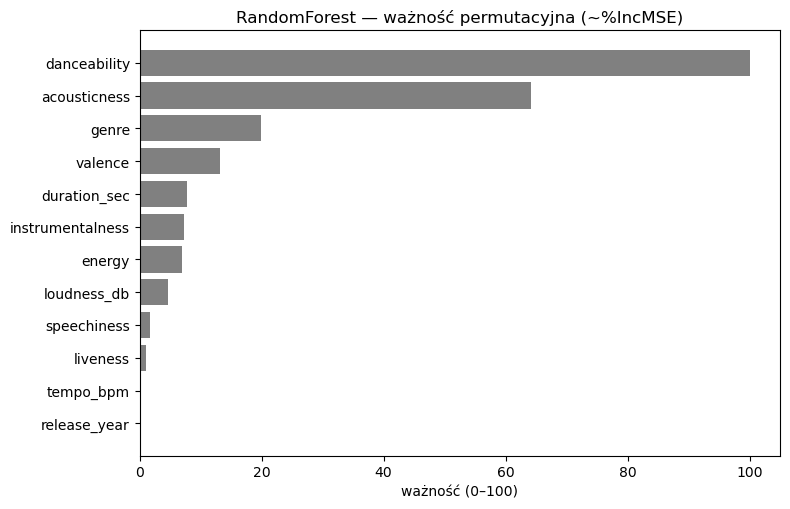

In [31]:
var_imp(pd.Series(rf.regressor_.named_steps["reg"].feature_importances_, index=feature_names(rf)),
        "RandomForest — ważność (spadek zanieczyszczenia, ~IncNodePurity)")

perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1,
                              scoring=metrics.make_scorer(r2_log))
var_imp(pd.Series(perm.importances_mean, index=X_test.columns),
        "RandomForest — ważność permutacyjna (~%IncMSE)")

## 9. Porównanie modeli

### Tabela porównawcza

In [32]:
res = pd.DataFrame(results).T
display(res.style.format({
    "R2_log_train": "{:.3f}", "R2_log_test": "{:.3f}", "R2_test": "{:.3f}",
    "MAE_test": "{:,.0f}", "MedAE_test": "{:,.0f}",
}))

,R2_log_train,R2_log_test,R2_test,MAE_test,MedAE_test
Dummy (średnia),0.000,-0.000,-0.043,"2,344,576","307,895"
LinearRegression,0.100,0.079,-0.034,"2,315,372","337,733"
Ridge (α = 2.5),0.100,0.079,-0.034,"2,315,314","335,727"
Lasso (α = 0.01),0.089,0.071,-0.036,"2,319,272","331,301"
RidgeCV,0.100,0.079,-0.034,"2,315,230","334,013"
LassoCV,0.100,0.079,-0.034,"2,315,254","333,744"
ElasticNetCV,0.100,0.079,-0.034,"2,315,226","334,357"
RandomForest,0.637,0.066,-0.034,"2,320,195","357,478"


### Wykres porównawczy

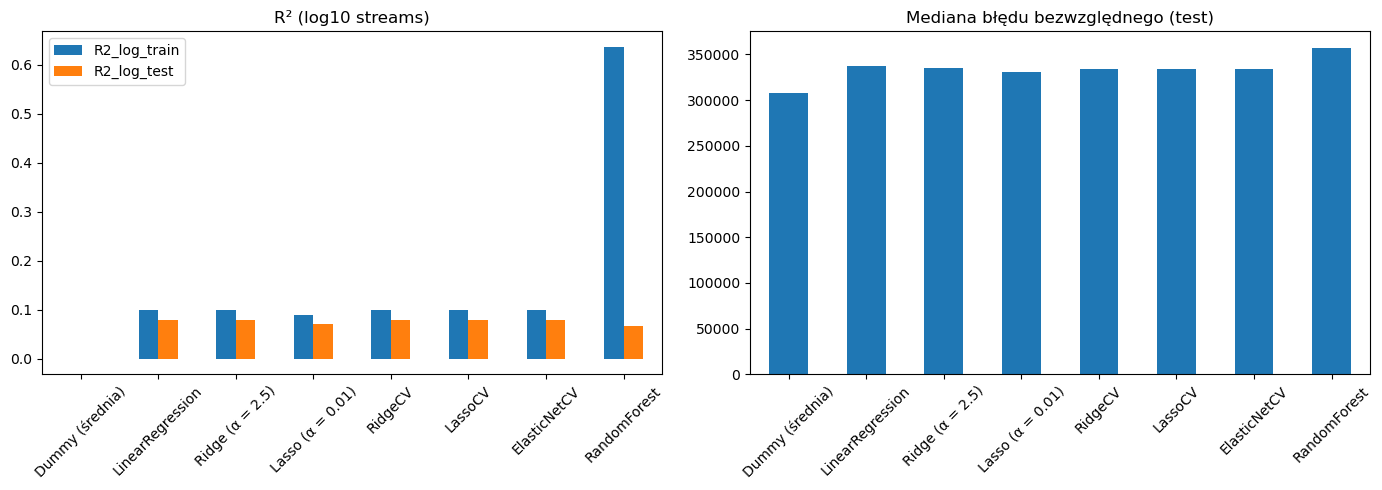

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
res[["R2_log_train", "R2_log_test"]].plot.bar(ax=axes[0])
axes[0].set_title("R² (log10 streams)")
axes[0].tick_params(axis="x", rotation=45)
res["MedAE_test"].plot.bar(ax=axes[1])
axes[1].set_title("Mediana błędu bezwzględnego (test)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### Wartości rzeczywiste a przewidywane

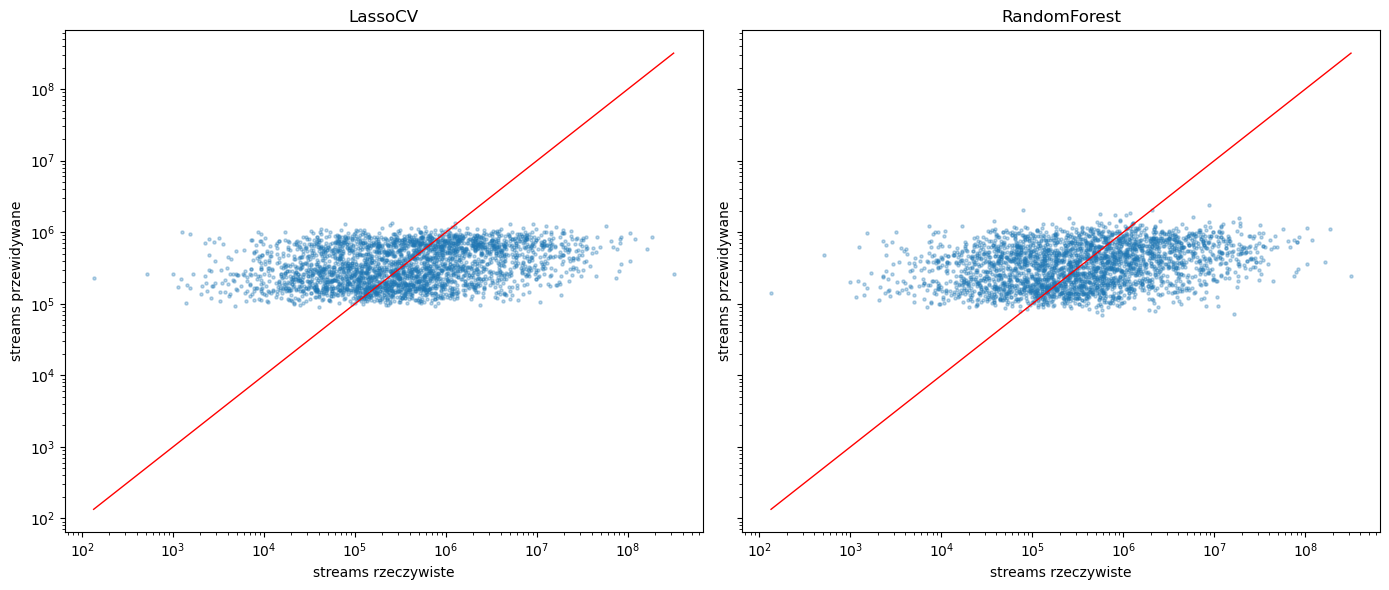

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, [("LassoCV", lasso_cv), ("RandomForest", rf)]):
    pred = model.predict(X_test)
    ax.scatter(y_test, pred, s=5, alpha=0.3)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, color="red", lw=1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("streams rzeczywiste")
    ax.set_ylabel("streams przewidywane")
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 10. Ważność cech — wszystkie modele

### Współczynniki modeli liniowych

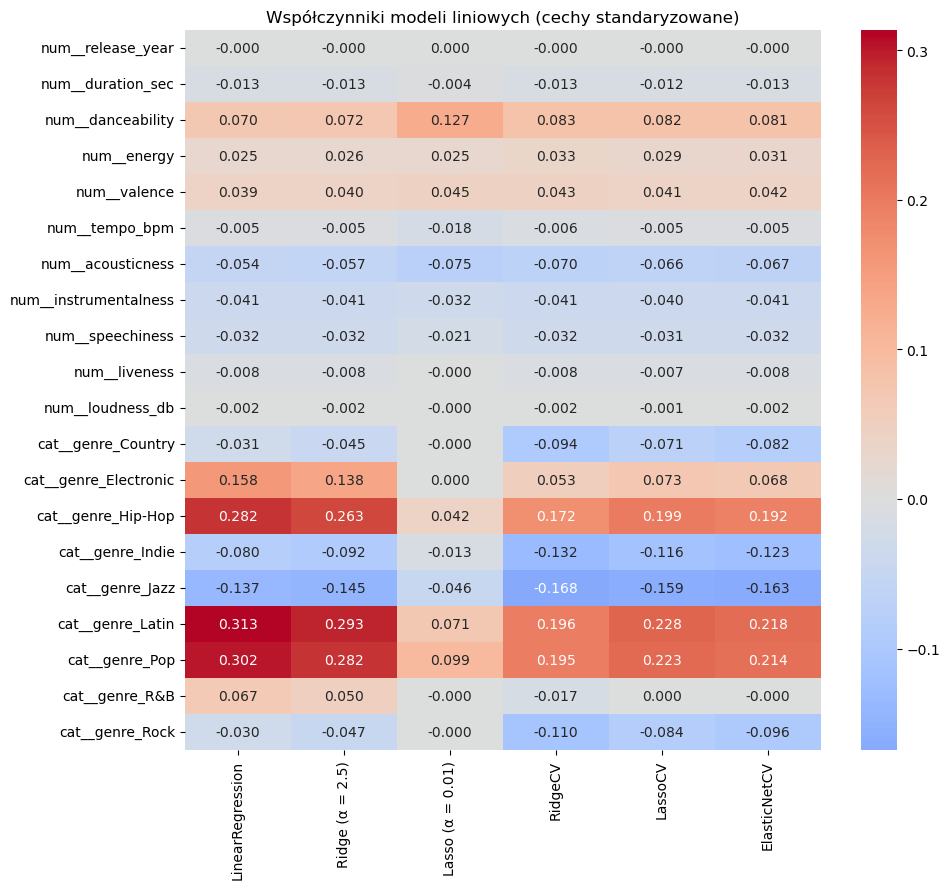

In [35]:
linear_models = {
    "LinearRegression": lin,
    "Ridge (α = 2.5)": ridge,
    "Lasso (α = 0.01)": lasso,
    "RidgeCV": ridge_cv,
    "LassoCV": lasso_cv,
    "ElasticNetCV": enet_cv,
}

coef_table = pd.DataFrame({
    name: model.regressor_.named_steps["reg"].coef_
    for name, model in linear_models.items()
}, index=feature_names(lin))

fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(coef_table, annot=True, fmt=".3f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Współczynniki modeli liniowych (cechy standaryzowane)")
plt.tight_layout()
plt.show()

### Permutation importance

In [36]:
all_models = {**linear_models, "RandomForest": rf}

perm_table = pd.DataFrame({
    name: permutation_importance(
        model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1,
        scoring=metrics.make_scorer(r2_log),
    ).importances_mean
    for name, model in all_models.items()
}, index=X_test.columns)

perm_table = perm_table.loc[perm_table.mean(axis=1).sort_values(ascending=False).index]
display(perm_table.round(4))

,LinearRegression,Ridge (α = 2.5),Lasso (α = 0.01),RidgeCV,LassoCV,ElasticNetCV,RandomForest
genre,0.0567,0.0540,0.0084,0.0410,0.0439,0.0434,0.0090
danceability,0.0072,0.0077,0.0358,0.0115,0.0111,0.0108,0.0499
acousticness,0.0058,0.0066,0.0144,0.0106,0.0094,0.0096,0.0315
valence,0.0014,0.0014,0.0028,0.0018,0.0016,0.0017,0.0055
instrumentalness,0.0019,0.0019,0.0015,0.0019,0.0019,0.0019,0.0025
energy,0.0009,0.0011,0.0019,0.0020,0.0015,0.0018,0.0023
speechiness,0.0014,0.0014,0.0010,0.0014,0.0014,0.0014,-0.0004
duration_sec,-0.0001,-0.0001,-0.0001,-0.0001,-0.0001,-0.0001,0.0028
loudness_db,0.0002,0.0002,0.0000,0.0002,0.0001,0.0001,0.0011
liveness,0.0001,0.0001,0.0000,0.0001,0.0001,0.0001,-0.0007


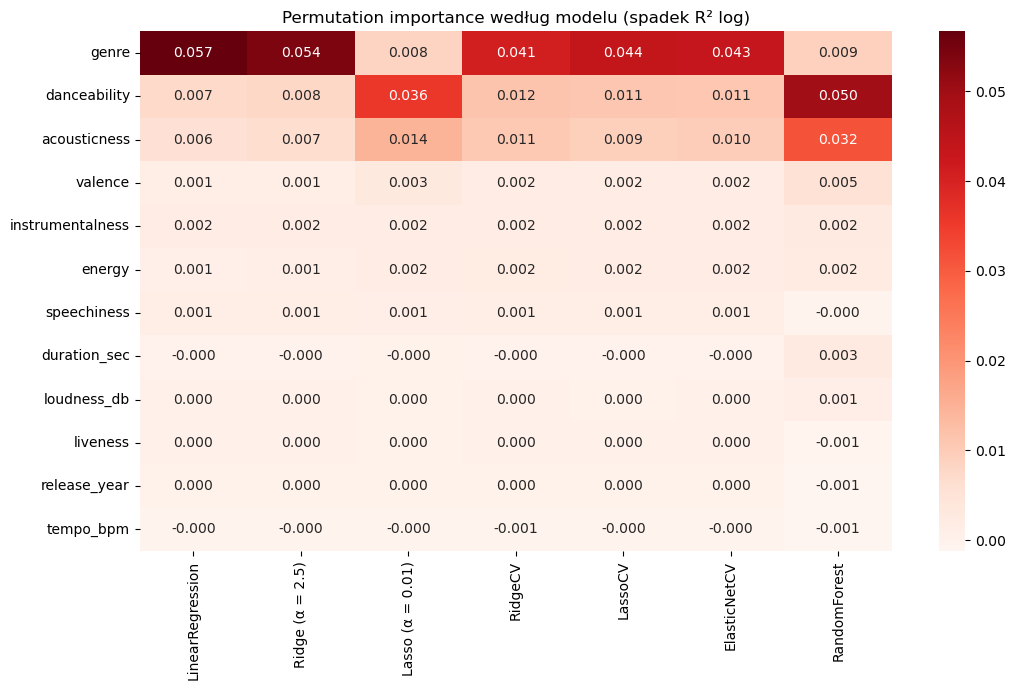

In [37]:
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(perm_table, annot=True, fmt=".3f", cmap="Reds", ax=ax)
ax.set_title("Permutation importance według modelu (spadek R² log)")
plt.tight_layout()
plt.show()